# 4. Optimización computacional

*Autores: María Carolina Cantillo Orozco (200179105) y Juan Camilo Oñoro Araujo (200177329)*

```{admonition} Qué responde este capítulo
:class: tip
**Pregunta.** ¿Cuánto cuesta entrenar y usar cada modelo, coincide con su complejidad teórica y qué versión
optimizada conviene?

**Respuesta corta.** La teoría predice bien el escalamiento: el SVM de núcleo completo crece casi
cuadráticamente (b = 1.88) y XGBoost `hist` es 9 veces más rápido que `exact` con el mismo F1. Pero no toda
versión «optimizada» conviene con estos datos: lbfgs le gana a SAGA, la búsqueda exhaustiva de KNN a KD-Tree, y
FAISS solo compensa con cientos de miles de viviendas. El 91 % del tiempo de una evaluación es construir
árboles.
```

El presupuesto de cómputo condicionó el diseño (capítulo 2): con las 257 273 viviendas, la validación anidada
de las 156 combinaciones costaba unas 630 horas-CPU. Este capítulo mide, para cada familia de modelos, una
versión **estándar** y una **optimizada**, y contrasta el orden de complejidad teórico con el tiempo medido.

**Método.** Se entrenan las variantes con n = 1 000 a 32 000 viviendas (las mismas p variables del pipeline
tras el preprocesamiento), con la mediana de 3 repeticiones del tiempo, la memoria pico (`tracemalloc`) y el F1
macro en un conjunto fijo de 10 000 viviendas. El **exponente empírico** *b* sale de ajustar
$\log t = a + b \log n$: un algoritmo $O(n)$ debería dar $b \approx 1$, uno $O(n^2)$, $b \approx 2$.

## 4.1 Complejidad teórica

| Modelo | Estándar | Optimizado | Entrenamiento | Inferencia (por consulta) |
|---|---|---|---|---|
| KNN | búsqueda exhaustiva | KD-Tree / Ball Tree · FAISS (IVF, HNSW) | O(1) (exhaustiva) · O(n·log n) (árbol) · IVF: O(n·p·iter) para k-medias · HNSW: O(n·log n) | O(n·p) · O(log n) en dimensión baja, se degrada hacia O(n) con p alto · IVF: O((n/√n)·nprobe·p) · HNSW: ≈ O(log n) |
| Logística / Ridge / Lasso | lbfgs / Cholesky | SAGA | lbfgs: O(n·p) por iteración · Cholesky: O(n·p² + p³) | O(p) |
| Naive Bayes | `fit` | `partial_fit` por lotes | O(n·p) (una pasada), memoria O(p·K) | O(p·K) |
| XGBoost | `exact` | `hist` + early stopping | exact: O(n·p·log n) para ordenar · hist: O(n·p) para el histograma y O(bins·p) por nodo | O(árboles·profundidad) |
| SVM | núcleo RBF completo (`SVC`) | Nyström + LinearSVC · SGD | O(n²)–O(n³) · O(n·m² + n·m) · O(n·p) por época | O(vectores soporte·p) · O(m·p) · O(p) |

(*n* = viviendas, *p* = variables, *K* = clases, *m* = componentes de Nyström.)

## 4.2 Tiempo medido frente a la teoría

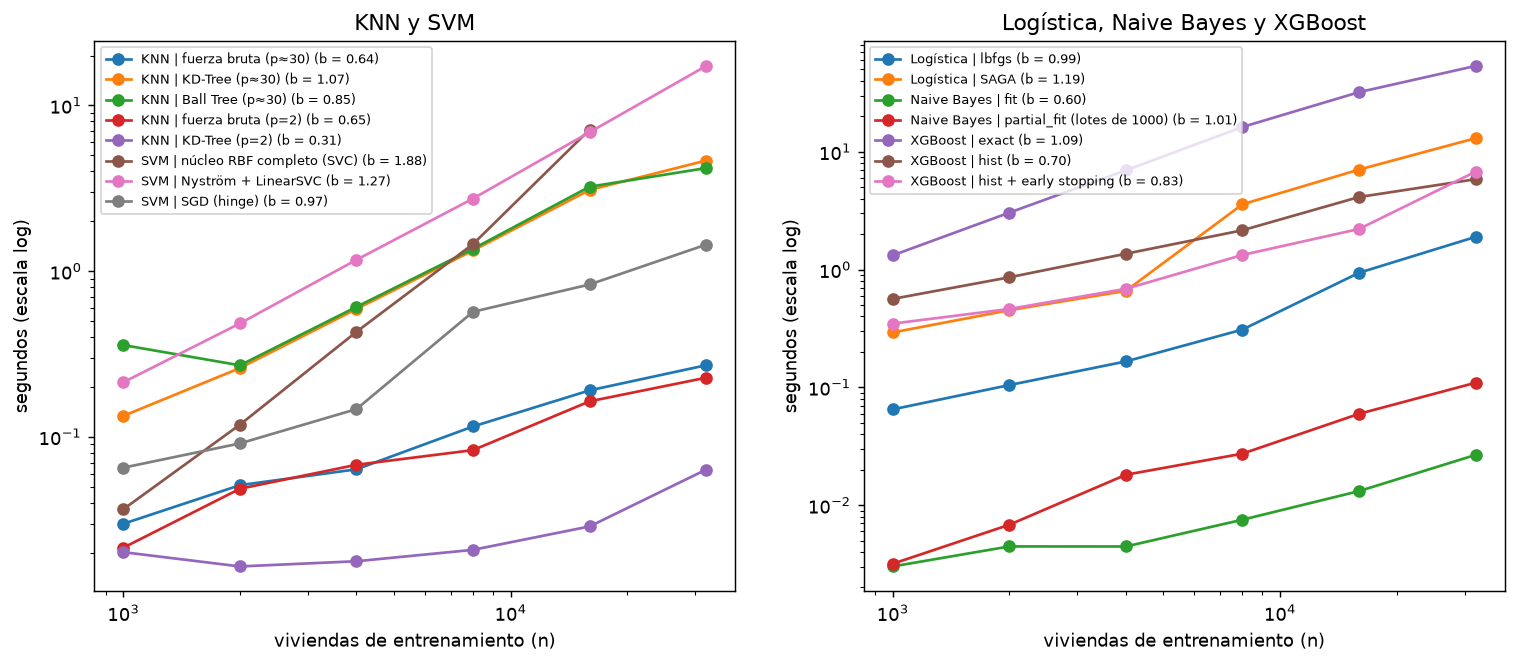

n,1000,2000,4000,8000,16000,32000,exponente b
variante,,,,,,,
KNN | Ball Tree (p≈30),0.358,0.270,0.608,1.363,3.231,4.186,0.85
KNN | KD-Tree (p=2),0.020,0.017,0.018,0.021,0.029,0.063,0.31
KNN | KD-Tree (p≈30),0.134,0.260,0.591,1.333,3.088,4.650,1.07
KNN | fuerza bruta (p=2),0.021,0.049,0.068,0.083,0.164,0.227,0.65
KNN | fuerza bruta (p≈30),0.030,0.051,0.064,0.116,0.191,0.271,0.64
Logística | SAGA,0.293,0.452,0.660,3.582,7.059,13.038,1.19
Logística | lbfgs,0.065,0.105,0.166,0.309,0.939,1.895,0.99
Naive Bayes | fit,0.003,0.004,0.004,0.008,0.013,0.027,0.60
Naive Bayes | partial_fit (lotes de 1000),0.003,0.007,0.018,0.027,0.060,0.109,1.01


,"tiempo (n = 32,000)",memoria pico (MB),F1 macro en validación
variante,,,
KNN | fuerza bruta (p≈30),0.271,1.895,NaN
KNN | KD-Tree (p≈30),4.650,4.322,NaN
KNN | Ball Tree (p≈30),4.186,3.748,NaN
KNN | fuerza bruta (p=2),0.227,3.347,NaN
KNN | KD-Tree (p=2),0.063,3.744,NaN
Logística | lbfgs,1.895,3.669,0.702
Logística | SAGA,13.038,2.576,0.700
Naive Bayes | fit,0.027,9.029,0.267
Naive Bayes | partial_fit (lotes de 1000),0.109,0.354,0.280


In [1]:
import pandas as pd

from _comun import figura, leer_json

CX = leer_json("complejidad.json")
figura("escalamiento.png")
if CX:
    med = pd.DataFrame(CX["mediciones"])
    t = med.pivot_table(index="variante", columns="n", values="segundos").round(3)
    t["exponente b"] = pd.Series(CX["exponentes"]).round(2)
    display(t)
    m32 = med[med.n == med.n.max()].set_index("variante")[["segundos", "memoria_MB", "f1_validacion"]].round(3)
    m32.columns = [f"tiempo (n = {med.n.max():,})", "memoria pico (MB)", "F1 macro en validación"]
    display(m32)

**Lectura.** El exponente empírico *b* coincide con la teoría donde la teoría es clara, y se desvía por
razones que se pueden explicar:

- **SVM con núcleo completo: b = 1.88**, casi cuadrático, como predice O(n²)–O(n³): de 1 000 a 16 000 viviendas el
  tiempo se multiplica por 190 (0.04 s → 7.1 s), y con 32 000 ya no se intentó. Nyström + LinearSVC (b = 1.27) y SGD
  (b = 0.97) escalan casi linealmente; con 16 000 viviendas Nyström cuesta lo mismo que el SVC (6.9 s frente a
  7.1 s), y la brecha crece con n por la diferencia de exponentes (1.88 frente a 1.27).
- **XGBoost:** `exact` tiene b = 1.09 (O(n·log n) por árbol) y tarda 53.6 s con 32 000 viviendas; `hist` tiene
  b = 0.70 y tarda 5.9 s: **9 veces más rápido con el mismo F1** (0.889 frente a 0.890). Su b < 1 refleja costos
  fijos (construir los histogramas, inicializar el booster) que pesan más con n pequeño. El early stopping usa
  entre 19 y 122 árboles en vez de 600, y con 32 000 viviendas sigue necesitando más árboles: por eso su b (0.83)
  es mayor que el de `hist` solo.
- **Logística:** lbfgs es lineal (b = 0.99) y **más rápida que SAGA** en todos los tamaños (1.9 s frente a 13.0 s
  con 32 000), con el mismo F1. SAGA conviene con datos dispersos o tan grandes que no caben en memoria; con 35
  variables densas, lbfgs converge en pocas iteraciones porque usa curvatura.
- **Naive Bayes:** `fit` es casi instantáneo (0.03 s con 32 000); `partial_fit` por lotes es 4 veces más lento por
  el costo de cada llamada, pero su memoria no crece con n (0.4 MB frente a 9 MB): es la opción si los datos no
  caben en memoria, no para ganar tiempo.
- **KNN:** con las 35 variables del modelo, la **fuerza bruta es la más rápida** (0.27 s con 32 000 viviendas y
  2 000 consultas) y KD-Tree es 17 veces más lenta (4.7 s, b = 1.07): con tantas dimensiones la poda del árbol casi
  no descarta ramas y queda una búsqueda lineal con más sobrecosto. Con solo las 2 coordenadas el árbol sí funciona:
  b = 0.31, consistente con O(log n) por consulta. La fuerza bruta tiene b = 0.64 porque usa productos de matrices
  (BLAS) muy eficientes, cuyo costo fijo domina con n pequeño.

El F1 de esta sección se mide en viviendas tomadas al azar (no en zonas nuevas) y solo sirve para comparar
variantes del mismo modelo, no con el resto del libro.

## 4.3 KNN: vecinos exactos frente a aproximados (FAISS)

KD-Tree y Ball Tree son exactos, pero con unas 30 variables su poda deja de funcionar (la «maldición de la
dimensión»: casi todos los puntos quedan a distancias parecidas) y la búsqueda vuelve a ser casi lineal. La
alternativa es **renunciar a la exactitud**: FAISS (Johnson, Douze y Jégou, 2019) ofrece índices aproximados.

- **IVF** (*inverted file*): k-medias con √n centroides; cada consulta solo revisa las `nprobe` = 8 listas más
  cercanas, así que mira ≈ 8/√n de las viviendas.
- **HNSW** (*hierarchical navigable small world*; Malkov y Yashunin, 2018): un grafo por capas donde cada punto
  se conecta con M = 32 vecinos; la búsqueda baja de capa en capa como en una lista con saltos, ≈ O(log n).

El precio es el **recall@30**: la fracción de los 30 vecinos exactos que el índice encuentra. Se mide con las
mismas variables preprocesadas, de 4 000 a 256 000 viviendas indexadas y 2 000 consultas del test, en un hilo.

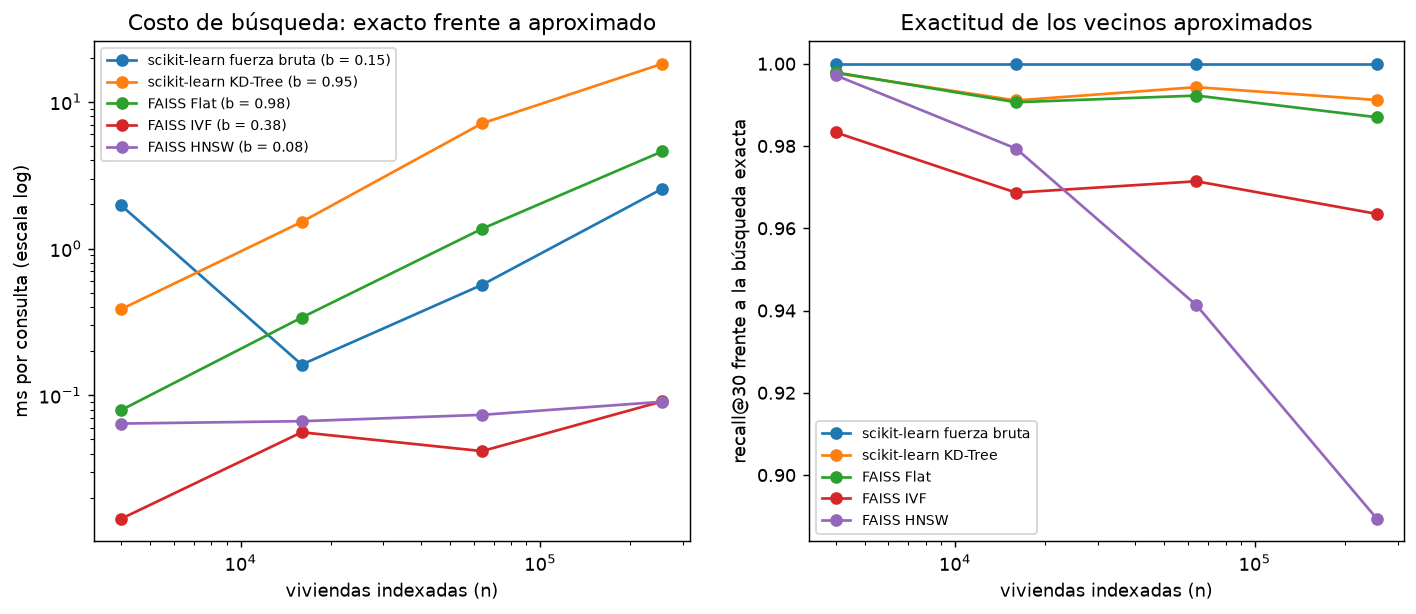

n,4000,16000,64000,256000,exponente b (búsqueda)
metodo,,,,,
FAISS Flat,0.079,0.339,1.364,4.600,0.98
FAISS HNSW,0.064,0.067,0.074,0.090,0.08
FAISS IVF,0.014,0.056,0.042,0.091,0.38
scikit-learn KD-Tree,0.386,1.518,7.127,18.181,0.95
scikit-learn fuerza bruta,1.967,0.162,0.566,2.560,0.15


,seg_construccion,ms_por_consulta,indice_MB,recall_at_30,f1_macro_voto
detalle,,,,,
scikit-learn fuerza bruta,0.007,2.560,35.840,1.000,0.510
scikit-learn KD-Tree,2.788,18.181,35.840,0.991,0.510
FAISS Flat (exacto),0.018,4.600,35.840,0.987,0.510
"FAISS IVF (nlist = 505, nprobe = 8)",3.602,0.091,37.963,0.963,0.513
"FAISS HNSW (M = 32, efSearch = 64)",18.225,0.090,105.513,0.889,0.532


In [2]:
FA = leer_json("complejidad_faiss.json")
figura("faiss_knn.png")
if FA:
    fm = pd.DataFrame(FA["mediciones"])
    display(fm.pivot_table(index="metodo", columns="n", values="ms_por_consulta").round(3)
            .assign(**{"exponente b (búsqueda)": pd.Series(FA["exponentes_busqueda"]).round(2)}))
    display(fm[fm.n == fm.n.max()].set_index("detalle")[["seg_construccion", "ms_por_consulta", "indice_MB",
                                                          "recall_at_30", "f1_macro_voto"]].round(3))

**Lectura.** Con 256 000 viviendas indexadas, los índices aproximados responden una consulta en **0.09 ms**,
frente a 2.6 ms de la fuerza bruta de scikit-learn (28 veces más rápido), 4.6 ms de FAISS exacto y 18 ms de
KD-Tree. Sus exponentes de búsqueda confirman la teoría: HNSW tiene b = 0.08 (casi constante, como O(log n)),
IVF b = 0.38 (cerca del √n esperado), y los exactos FAISS Flat y KD-Tree b ≈ 1 (lineales: con 35 variables,
KD-Tree ya no poda). La fuerza bruta de scikit-learn da un b engañoso (0.15) porque su primera medición
incluye el arranque de BLAS y porque BLAS puede usar varios hilos aunque el modelo tenga `n_jobs=1`.

**El precio es la exactitud y la construcción.** IVF encuentra el 96 % de los 30 vecinos exactos y HNSW el 89
% (con `efSearch` fijo, su recall baja a medida que crece n). HNSW es además caro de construir: 18 s y 105 MB,
el triple de la memoria de los datos, frente a 3.6 s y 38 MB de IVF. Aun así, **el F1 del voto no empeora**
(0.513 en IVF y 0.532 en HNSW, frente a 0.510 exacto): los vecinos que el índice cambia están casi a la misma
distancia que los exactos y suelen tener el mismo estrato. Los métodos exactos no llegan a un recall de 1 por
empates: viviendas del mismo edificio con variables idénticas.

Para predecir las 65 145 viviendas del test con las 257 273 de entrenamiento, la fuerza bruta tardaría unos
170 s y HNSW unos 6 s más 18 s de construcción. Con este tamaño la aproximación conviene; con la submuestra de
10 000 del pipeline combinatorio, la búsqueda exacta ya es suficientemente rápida.

## 4.4 Tabla comparativa: estándar frente a optimizado

Con n = 16 000 viviendas de entrenamiento (el mayor tamaño en que el SVM de núcleo completo es viable),
10 000 viviendas para medir la inferencia y el F1, mediana de 3 repeticiones y un hilo:

In [3]:
TB = leer_json("tabla_estandar_optimizado.json")
if TB:
    tb = pd.DataFrame(TB["filas"]).set_index("variante")
    tb = tb[["complejidad_entrenamiento", "complejidad_inferencia", "seg_entrenamiento", "seg_inferencia_10000",
             "memoria_pico_MB", "modelo_MB", "f1_macro"]]
    tb.columns = ["complejidad (entrenamiento)", "complejidad (inferencia)", "entrenamiento (s)",
                  "inferencia de 10 000 (s)", "memoria pico Python (MB)", "tamaño del modelo (MB)", "F1 macro"]
    display(tb.round(3))
else:
    print("(tabla pendiente)")

,complejidad (entrenamiento),complejidad (inferencia),entrenamiento (s),inferencia de 10 000 (s),memoria pico Python (MB),tamaño del modelo (MB),F1 macro
variante,,,,,,,
KNN | fuerza bruta,O(1),O(n·p) por consulta,0.003,0.883,0.794,4.609,0.719
KNN | FAISS HNSW,≈ O(n·log n),≈ O(log n) por consulta (aproximado),0.687,0.617,2.241,6.595,0.719
Logística | lbfgs,O(n·p·K) por iteración,O(p·K),1.258,0.002,1.888,0.002,0.701
Logística | SAGA,O(n·p·K) por época,O(p·K),7.826,0.002,1.296,0.002,0.687
Naive Bayes | fit,O(n·p) (todo en memoria),O(p·K),0.013,0.025,4.550,0.004,0.216
Naive Bayes | partial_fit,"O(n·p) por lotes, memoria O(p·K)",O(p·K),0.051,0.024,0.354,0.004,0.219
XGBoost | exact,O(T·n·p·log n),O(T·profundidad),35.896,0.190,0.135,2.395,0.836
XGBoost | hist + early stopping,"O(n·p) + O(T'·bins·p·nodos), T' ≤ T",O(T'·profundidad),11.632,0.578,0.158,7.279,0.862
SVM | SVC (núcleo RBF completo),O(n²·p) a O(n³),O(n_sv·p),9.524,8.780,4.612,2.661,0.792


**Lectura.** Con n = 16 000, la optimización conviene en tres familias y en dos no:

- **XGBoost:** `hist` con early stopping entrena en 11.6 s frente a 35.9 s de `exact`, y con mejor F1 (0.862 frente
  a 0.836), aunque usa 599 árboles frente a 200: con la tasa de aprendizaje de 0.05, el early stopping nunca llegó a
  detenerse antes de los 600. Por árbol, `hist` es unas 9 veces más barato. El costo de tener más árboles aparece
  en la inferencia (0.58 s frente a 0.19 s) y en el tamaño del modelo (7.3 MB frente a 2.4 MB).
- **SVM:** el núcleo completo da el mejor F1 (0.792), pero predecir 10 000 viviendas le toma 8.8 s, porque cada
  predicción se compara con todos sus vectores de soporte. Nyström + LinearSVC predice en 0.11 s (80 veces más
  rápido) a cambio de 0.036 de F1; con 16 000 viviendas todavía entrena más lento (13.7 s frente a 9.5 s), pero
  escala con b = 1.27 frente a 1.88 (sección 4.2). SGD es el más rápido en todo (0.6 s y 0.002 s), pero pierde 0.16
  de F1.
- **Naive Bayes:** `partial_fit` mantiene la memoria en 0.4 MB (frente a 4.5 MB) con el mismo F1; tarda 4 veces más,
  pero en milisegundos.
- **Logística:** SAGA es 6 veces más lenta que lbfgs (7.8 s frente a 1.3 s) y algo peor (0.687 frente a 0.701): con
  datos densos de 35 columnas, lbfgs es la opción; SAGA queda para datos dispersos o más grandes.
- **KNN:** con 16 000 viviendas, FAISS HNSW apenas mejora la inferencia (0.62 s frente a 0.88 s) y cuesta 0.69 s de
  construcción, con el mismo F1 (0.719). Su ventaja aparece con más datos: 28 veces más rápido con 256 000 (sección
  4.3).

## 4.5 Perfilamiento

Antes de optimizar conviene saber dónde se va el tiempo. Perfil (`cProfile`, ordenado por tiempo acumulado) de
una evaluación completa del pipeline más usado, XGBoost con SMOTE:

In [4]:
if CX:
    print("\n".join(CX["perfil_cprofile"].splitlines()[:40]))

         212295 function calls (210960 primitive calls) in 4.094 seconds

   Ordered by: cumulative time
   List reduced from 1265 to 18 due to restriction <18>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
     19/1    0.001    0.000    4.088    4.088 sklearn\base.py:1319(wrapper)
        1    0.000    0.000    4.087    4.087 imblearn\pipeline.py:451(fit)
        1    0.000    0.000    3.906    3.906 estrato3\modelos_propios.py:60(fit)
     13/2    0.000    0.000    3.901    1.951 xgboost\core.py:732(inner_f)
        1    0.000    0.000    3.901    3.901 xgboost\sklearn.py:1719(fit)
        1    0.001    0.001    3.787    3.787 xgboost\training.py:52(train)
      150    3.733    0.025    3.745    0.025 xgboost\core.py:2362(update)
        1    0.000    0.000    0.181    0.181 imblearn\pipeline.py:394(_fit)
      9/2    0.000    0.000    0.181    0.090 joblib\memory.py:325(__call__)
        1    0.000    0.000    0.122    0.122 imblearn\pipeline.py:1366(_fit_

**Lectura.** De los 4.1 s de una evaluación completa (preprocesamiento → SMOTE → XGBoost, 6 000 viviendas),
**3.7 s (91 %) son la construcción de los 150 árboles** (`xgboost.core.update`). El preprocesamiento (0.12 s)
y SMOTE (≈ 0.06 s) juntos suman 0.18 s, el 4 %. Por eso las optimizaciones que importan son las del modelo
(`hist`, early stopping, menos árboles o menor profundidad), no las del preprocesamiento; optimizar el
ColumnTransformer sería optimizar prematuramente.

## 4.6 Paralelismo

El pipeline combinatorio se paraleliza **entre tareas** (cada combinación × pliegue externo es independiente)
con `joblib` y el backend `loky` (procesos), y cada modelo corre con un solo hilo (`n_jobs=1`) para no
sobresuscribir los núcleos. Aceleración medida al validar un Random Forest en 8 pliegues:

In [5]:
if CX:
    ac = pd.Series(CX["aceleracion_n_jobs"]).astype(float)
    display(pd.DataFrame({"segundos": ac.round(1), "aceleración": (ac.iloc[0] / ac).round(2)}))
    print(CX["gpu"])

,segundos,aceleración
1,12.0,1.00
2,10.8,1.11
4,10.4,1.16
8,12.4,0.97


No disponible: el portátil (Intel Core i5-8265U) no tiene GPU NVIDIA para device='cuda'.


**Lectura.** En esta prueba el paralelismo casi no ayuda (12.0 s con 1 proceso, 10.4 s con 4 y 12.4 s con 8):
cada pliegue tarda ≈ 1.5 s, y arrancar los procesos de `loky`, importar las librerías y enviarles los datos
cuesta lo mismo o más. Con 8 procesos además se comparten 4 núcleos físicos (hyper-threading), así que cada
uno va más lento.

En el pipeline combinatorio, en cambio, cada tarea (una combinación en un pliegue externo, con sus 12
evaluaciones × 3 pliegues internos) dura minutos, y el sobrecosto es despreciable: las 640 tareas sumaron
**38.4 horas** de tiempo de tarea y terminaron en **4.8 horas** de reloj con 8 procesos, sin procesos ociosos.
Esas 38.4 horas están medidas con la máquina llena, así que la aceleración frente a un solo proceso es menor
que 8; con 4 núcleos físicos, lo esperable es entre 4 y 5. La regla práctica: **paralelizar entre tareas
grandes e independientes, no dentro de tareas de un segundo**, y fijar `n_jobs=1` dentro de cada modelo para
no sobresuscribir los núcleos.

**GPU.** El portátil (Intel Core i5-8265U) no tiene GPU NVIDIA, así que no se pudo medir XGBoost con
`device="cuda"`. **Cómputo distribuido.** Con 640 tareas de minutos y datos que caben en memoria, joblib en
una sola máquina basta; Dask o Ray se justificarían con el conjunto completo (257 273 viviendas) en varias
máquinas, donde la validación anidada costaba unas 630 horas-CPU.